# Chapter 10: Clustering Techniques

*Summary notebook untuk **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025) — Chapter 10.*

Bab ini membahas **clustering**, teknik *unsupervised learning* untuk menemukan kelompok alami pada data tanpa label target. Kita akan mempelajari K-means, hierarchical clustering, DBSCAN, metrik evaluasi, pemilihan algoritma, serta teknik lanjutan seperti Spectral Clustering dan Gaussian Mixture Models (GMM).

Contoh dibuat menggunakan dataset bawaan scikit-learn atau data sintetis agar notebook dapat dijalankan tanpa mengunduh dataset eksternal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import sklearn
print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version: {np.__version__}")

scikit-learn version: 1.8.0
NumPy version: 2.3.5


> **Catatan versi.** Buku menargetkan scikit-learn 1.5+. Contoh di bawah menggunakan API umum yang tersedia pada versi modern scikit-learn. Pada clustering, nomor label cluster yang dihasilkan dapat berbeda antar-run atau antaralgoritma; yang utama adalah pola pengelompokannya, bukan angka labelnya.

## 1. Introduction to Clustering

### Ringkasan

**Clustering** mengelompokkan titik data yang mirip tanpa membutuhkan label target. Karena tidak ada jawaban benar yang diberikan saat pelatihan, clustering termasuk *unsupervised learning*.

Contoh penerapan:
- Segmentasi pelanggan berdasarkan perilaku pembelian.
- Pengelompokan dokumen atau artikel berdasarkan kemiripan.
- Eksplorasi pola pada data sensor.
- Membantu menemukan kelompok atau struktur awal sebelum membangun model supervised.

Tantangan utamanya adalah memilih algoritma dan parameter yang sesuai, menentukan jumlah cluster, serta menangani noise dan bentuk cluster yang tidak teratur.

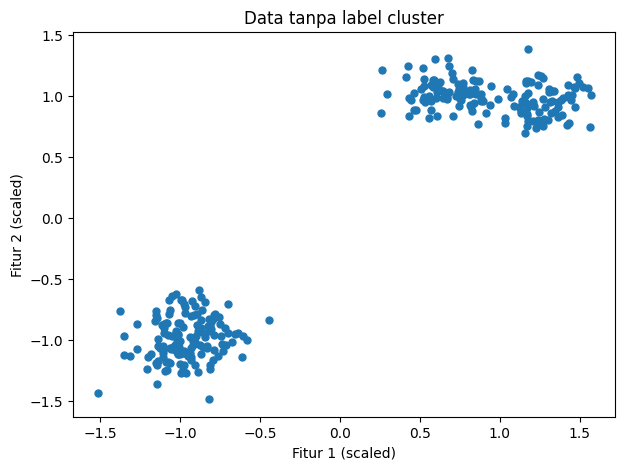

In [2]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

X_demo, y_demo = make_blobs(
    n_samples=300, centers=4, cluster_std=0.75, random_state=2024
)
X_demo_scaled = StandardScaler().fit_transform(X_demo)

plt.figure(figsize=(7, 5))
plt.scatter(X_demo_scaled[:, 0], X_demo_scaled[:, 1], s=25)
plt.title("Data tanpa label cluster")
plt.xlabel("Fitur 1 (scaled)")
plt.ylabel("Fitur 2 (scaled)")
plt.show()

**Membaca hasil.** Plot menunjukkan sebaran data tanpa menggunakan label kelas. Dalam situasi nyata, struktur kelompok belum tentu terlihat jelas; clustering membantu mengeksplorasi apakah ada kelompok yang masuk akal berdasarkan fitur yang tersedia.

## 2. K-means Clustering

### Ringkasan

**K-means** membagi data menjadi `k` cluster. Algoritma memulai centroid, memasukkan setiap titik ke centroid terdekat, lalu memperbarui posisi centroid berdasarkan rata-rata titik dalam cluster. Proses berulang hingga konvergen atau mencapai batas iterasi.

Parameter penting:
- `n_clusters`: jumlah cluster yang ingin dicari (`k`).
- `n_init`: jumlah inisialisasi yang dicoba untuk mengurangi dampak pemilihan centroid awal.
- `random_state`: membuat hasil lebih mudah direproduksi.

K-means relatif efisien, tetapi cenderung bekerja lebih baik untuk cluster yang kompak dan kira-kira bulat. Skala fitur dapat memengaruhi jarak sehingga standardisasi sering berguna.

Inertia: 10.829
Jumlah anggota per cluster: [83 77 73 67]


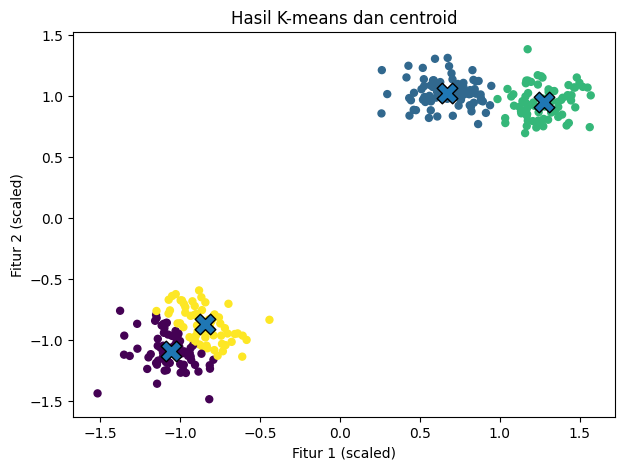

In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=2024, n_init=10)
labels_kmeans = kmeans.fit_predict(X_demo_scaled)
centers = kmeans.cluster_centers_

print("Inertia:", round(kmeans.inertia_, 3))
print("Jumlah anggota per cluster:", np.bincount(labels_kmeans))

plt.figure(figsize=(7, 5))
plt.scatter(X_demo_scaled[:, 0], X_demo_scaled[:, 1], c=labels_kmeans, s=25, cmap="viridis")
plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=220, edgecolor="black")
plt.title("Hasil K-means dan centroid")
plt.xlabel("Fitur 1 (scaled)")
plt.ylabel("Fitur 2 (scaled)")
plt.show()

**Interpretasi.** Warna menunjukkan cluster yang ditemukan, sedangkan tanda `X` menunjukkan centroid. `inertia_` adalah jumlah kuadrat jarak titik terhadap centroid cluster masing-masing; nilai ini dapat digunakan saat membandingkan beberapa nilai `k`, tetapi cenderung turun ketika jumlah cluster ditambah.

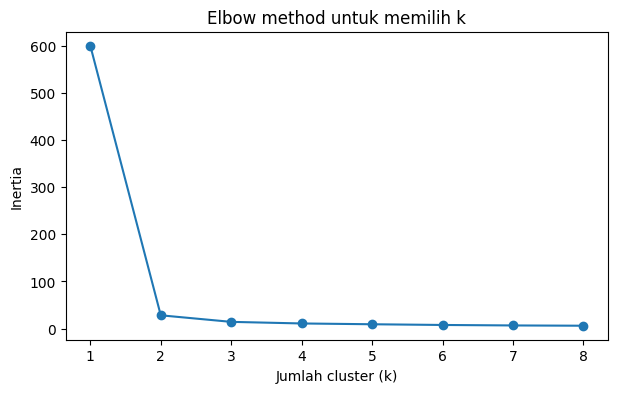

In [4]:
# Metode elbow: membandingkan inertia untuk beberapa nilai k
inertias = []
ks = range(1, 9)
for k in ks:
    model = KMeans(n_clusters=k, random_state=2024, n_init=10)
    model.fit(X_demo_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(ks), inertias, marker="o")
plt.xticks(list(ks))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow method untuk memilih k")
plt.show()

**Catatan.** Elbow method mencari titik ketika penambahan cluster tidak lagi menurunkan inertia secara drastis. Titik elbow tidak selalu jelas, sehingga sebaiknya dikombinasikan dengan pemahaman domain dan metrik lain.

## 3. Hierarchical Clustering

### Ringkasan

**Hierarchical clustering** membangun struktur cluster bertingkat. Pada pendekatan *agglomerative*, setiap titik awalnya merupakan cluster sendiri, lalu cluster yang paling dekat digabungkan secara bertahap.

Parameter dan konsep penting:
- `n_clusters`: jumlah cluster akhir yang diinginkan.
- `linkage`: cara menghitung jarak antarcluster, misalnya `ward`, `complete`, `average`, atau `single`.
- Dendrogram: visualisasi penggabungan cluster pada berbagai tingkat jarak.

Metode ini tidak memerlukan centroid seperti K-means dan dapat membantu memahami struktur bertingkat, tetapi biasanya lebih mahal secara komputasi pada dataset besar.

Jumlah anggota per cluster: [82 75 75 68]


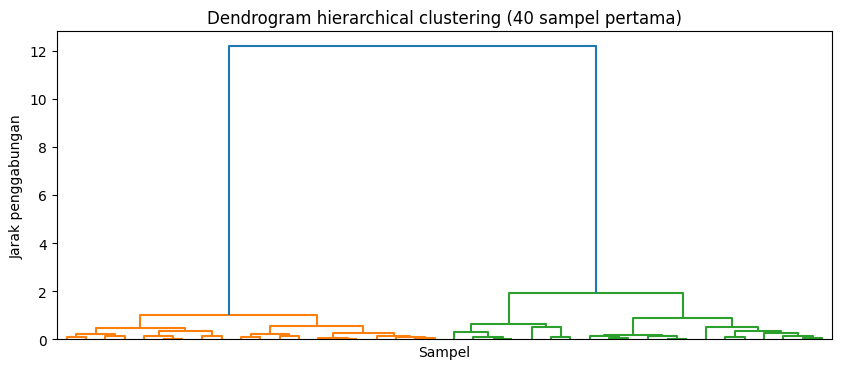

In [5]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

agg = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg.fit_predict(X_demo_scaled)
print("Jumlah anggota per cluster:", np.bincount(labels_agg))

# Dendrogram dibuat dari sampel terbatas agar tetap mudah dibaca
Z = linkage(X_demo_scaled[:40], method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, no_labels=True)
plt.title("Dendrogram hierarchical clustering (40 sampel pertama)")
plt.xlabel("Sampel")
plt.ylabel("Jarak penggabungan")
plt.show()

**Interpretasi.** Label dari AgglomerativeClustering menunjukkan pembagian cluster akhir. Pada dendrogram, cabang yang bergabung pada jarak lebih tinggi menunjukkan kelompok yang relatif lebih berbeda. Dendrogram di sini hanya memakai 40 sampel pertama untuk menjaga keterbacaan visual; hasil tersebut bukan representasi lengkap seluruh dataset.

## 4. Density-Based Clustering with DBSCAN

### Ringkasan

**DBSCAN** membentuk cluster berdasarkan kepadatan titik dan dapat menandai titik yang tidak masuk cluster sebagai noise (`-1`). DBSCAN tidak meminta jumlah cluster di awal dan dapat menemukan bentuk cluster non-konveks.

Parameter utama:
- `eps`: radius lingkungan untuk menentukan kedekatan titik.
- `min_samples`: jumlah minimum titik dalam lingkungan agar suatu titik dianggap titik inti.

DBSCAN sensitif terhadap skala fitur dan pilihan parameter. Jika kepadatan cluster sangat bervariasi, satu pasangan parameter mungkin tidak cocok untuk semua kelompok.

Jumlah cluster (tanpa noise): 2
Jumlah titik noise: 0


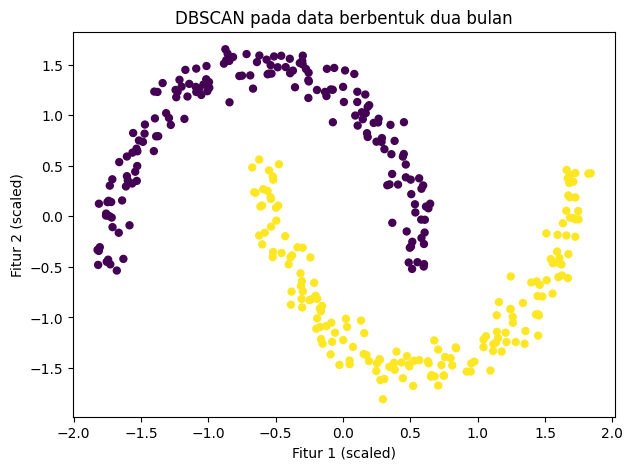

In [6]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X_moons, _ = make_moons(n_samples=350, noise=0.06, random_state=2024)
X_moons_scaled = StandardScaler().fit_transform(X_moons)

dbscan = DBSCAN(eps=0.25, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_moons_scaled)

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = int(np.sum(labels_dbscan == -1))
print("Jumlah cluster (tanpa noise):", n_clusters_dbscan)
print("Jumlah titik noise:", n_noise)

plt.figure(figsize=(7, 5))
plt.scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_dbscan, s=25, cmap="viridis")
plt.title("DBSCAN pada data berbentuk dua bulan")
plt.xlabel("Fitur 1 (scaled)")
plt.ylabel("Fitur 2 (scaled)")
plt.show()

**Membaca hasil.** DBSCAN dapat memisahkan bentuk melengkung seperti dua bulan, sementara K-means cenderung membagi ruang berdasarkan centroid. Titik dengan label `-1` dianggap noise menurut nilai `eps` dan `min_samples` yang dipilih, bukan otomatis berarti data tersebut salah.

## 5. Cluster Evaluation Metrics

### Ringkasan

Evaluasi clustering lebih menantang dibanding klasifikasi karena biasanya tidak tersedia label target. Beberapa metrik internal yang umum digunakan:

- **Silhouette score**: berkisar dari -1 sampai 1; nilai lebih tinggi umumnya menunjukkan cluster yang lebih terpisah dan kompak.
- **Davies–Bouldin index**: nilai lebih rendah umumnya lebih baik.
- **Calinski–Harabasz score**: nilai lebih tinggi umumnya lebih baik.

Metrik perlu ditafsirkan sesuai bentuk data dan algoritma. Silhouette score tidak terdefinisi dengan baik bila label hanya membentuk satu cluster atau setiap titik menjadi cluster sendiri. Untuk DBSCAN, noise juga perlu dipertimbangkan secara eksplisit.

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Evaluasi K-means pada data sintetis berkelompok
metrics = {
    "Silhouette score": silhouette_score(X_demo_scaled, labels_kmeans),
    "Davies-Bouldin index": davies_bouldin_score(X_demo_scaled, labels_kmeans),
    "Calinski-Harabasz score": calinski_harabasz_score(X_demo_scaled, labels_kmeans),
}
for name, value in metrics.items():
    print(f"{name}: {value:.3f}")

Silhouette score: 0.483
Davies-Bouldin index: 0.812
Calinski-Harabasz score: 5368.151


**Interpretasi.** Gunakan beberapa metrik dan visualisasi, bukan satu angka saja. Silhouette yang tinggi sering menandakan pemisahan yang baik, sementara Davies–Bouldin yang rendah umumnya lebih baik. Metrik internal tidak menjamin cluster yang dihasilkan bermakna bagi kebutuhan bisnis atau penelitian.

In [8]:
# Silhouette score untuk beberapa pilihan k
silhouette_by_k = {}
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=2024, n_init=10)
    labels = model.fit_predict(X_demo_scaled)
    silhouette_by_k[k] = silhouette_score(X_demo_scaled, labels)

pd.Series(silhouette_by_k, name="Silhouette score").rename_axis("k").to_frame()

,Silhouette score
k,
2,0.865948
3,0.739914
4,0.483028
5,0.493693
6,0.418797
7,0.390848


## 6. Choosing the Right Clustering Algorithm

### Ringkasan

Pemilihan algoritma bergantung pada karakteristik data, bentuk cluster, noise, skala dataset, dan parameter yang dapat ditentukan.

| Karakteristik data | Pilihan awal yang dapat dicoba |
|---|---|
| Cluster kompak dan kira-kira bulat | K-means |
| Struktur bertingkat atau dataset relatif kecil | Hierarchical / Agglomerative Clustering |
| Cluster dengan bentuk tidak beraturan dan adanya noise | DBSCAN |
| Dataset besar yang membutuhkan varian K-means lebih efisien | MiniBatchKMeans |
| Batas cluster non-linear yang kompleks | Spectral Clustering |
| Cluster menyerupai distribusi probabilistik/elliptical | Gaussian Mixture Model |

Tabel ini merupakan panduan awal, bukan aturan mutlak. Visualisasikan data jika memungkinkan, pertimbangkan standardisasi, lalu bandingkan beberapa pendekatan dan nilai apakah cluster berguna untuk konteks masalah.

In [9]:
from sklearn.cluster import MiniBatchKMeans

models = {
    "K-means": KMeans(n_clusters=4, random_state=2024, n_init=10),
    "Agglomerative": AgglomerativeClustering(n_clusters=4),
    "DBSCAN": DBSCAN(eps=0.25, min_samples=5),
}

# Contoh perbandingan jumlah cluster pada dataset berbentuk blob
for name, model in models.items():
    labels = model.fit_predict(X_demo_scaled)
    cluster_ids = set(labels) - {-1}
    noise_count = int(np.sum(labels == -1)) if name == "DBSCAN" else 0
    print(f"{name}: {len(cluster_ids)} cluster, {noise_count} titik noise")

K-means: 4 cluster, 0 titik noise
Agglomerative: 4 cluster, 0 titik noise
DBSCAN: 2 cluster, 1 titik noise


**Catatan interpretasi.** Perbandingan di atas menggunakan dataset berbentuk blob yang cenderung cocok untuk K-means. Dataset lain, terutama yang memiliki bentuk melengkung atau kepadatan tidak seragam, dapat menghasilkan perbandingan berbeda. Untuk pemilihan yang adil, evaluasi juga data dengan struktur yang sesuai dengan masalah sebenarnya.

## 7. Advanced Clustering Techniques

### Ringkasan

Dua teknik lanjutan yang dibahas dalam bab ini adalah:

- **Spectral Clustering**: memanfaatkan hubungan kemiripan antar titik dan dapat menangani struktur cluster non-konveks.
- **Gaussian Mixture Model (GMM)**: model probabilistik yang mengasumsikan data berasal dari campuran beberapa distribusi Gaussian. GMM memberi probabilitas keanggotaan setiap titik pada komponen, sehingga disebut *soft clustering*.

Spectral Clustering dapat membutuhkan komputasi dan memori lebih besar pada dataset besar. GMM fleksibel untuk cluster yang berbentuk elips, tetapi hasilnya bergantung pada asumsi distribusi dan jumlah komponen.

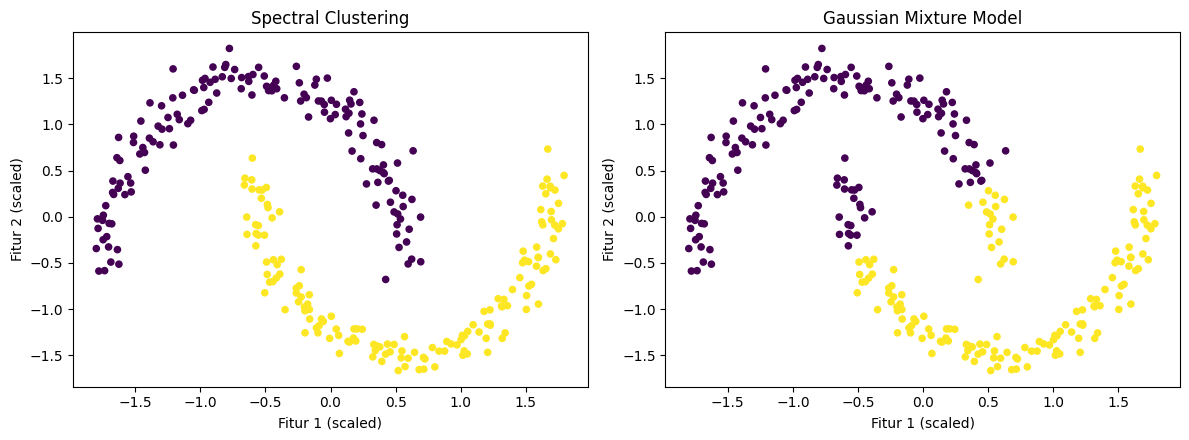

Bentuk matriks probabilitas GMM: (300, 2)
Probabilitas keanggotaan 5 titik pertama:
 [[0.39  0.61 ]
 [0.051 0.949]
 [0.001 0.999]
 [1.    0.   ]
 [1.    0.   ]]


In [10]:
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture

X_moons, _ = make_moons(n_samples=300, noise=0.06, random_state=2024)
X_moons_scaled = StandardScaler().fit_transform(X_moons)

spectral = SpectralClustering(
    n_clusters=2, affinity="nearest_neighbors", random_state=2024
)
labels_spectral = spectral.fit_predict(X_moons_scaled)

gmm = GaussianMixture(n_components=2, random_state=2024)
labels_gmm = gmm.fit_predict(X_moons_scaled)
probabilities_gmm = gmm.predict_proba(X_moons_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_spectral, s=20, cmap="viridis")
axes[0].set_title("Spectral Clustering")
axes[1].scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_gmm, s=20, cmap="viridis")
axes[1].set_title("Gaussian Mixture Model")
for ax in axes:
    ax.set_xlabel("Fitur 1 (scaled)")
    ax.set_ylabel("Fitur 2 (scaled)")
plt.tight_layout()
plt.show()

print("Bentuk matriks probabilitas GMM:", probabilities_gmm.shape)
print("Probabilitas keanggotaan 5 titik pertama:\n", np.round(probabilities_gmm[:5], 3))

**Interpretasi.** Spectral Clustering menggunakan hubungan lokal antar titik sehingga dapat memisahkan struktur berbentuk bulan. GMM menghasilkan probabilitas keanggotaan untuk setiap komponen; satu titik dapat memiliki probabilitas yang tersebar pada beberapa cluster. Pada data berbentuk bulan, asumsi Gaussian GMM mungkin tidak ideal, sehingga perbandingan ini menunjukkan bahwa algoritma berbeda memiliki asumsi dan kemampuan berbeda.

## Kesimpulan Chapter 10

- Clustering adalah *unsupervised learning* untuk menemukan kelompok tanpa label target.
- K-means efisien untuk cluster kompak, tetapi perlu menentukan `k` dan sensitif terhadap skala fitur.
- Hierarchical clustering menunjukkan struktur penggabungan cluster dan dapat divisualisasikan dengan dendrogram.
- DBSCAN mendeteksi cluster berbasis kepadatan dan dapat menandai noise.
- Silhouette, Davies–Bouldin, dan Calinski–Harabasz membantu mengevaluasi cluster, tetapi harus ditafsirkan bersama visualisasi dan konteks masalah.
- Spectral Clustering dan GMM dapat menangani struktur atau model probabilistik yang lebih kompleks.

### Latihan mandiri

1. Ubah `n_clusters` pada K-means dan amati perubahan inertia serta silhouette score.
2. Coba beberapa nilai `eps` dan `min_samples` pada DBSCAN. Catat perubahan jumlah cluster dan titik noise.
3. Bandingkan K-means, Agglomerative Clustering, dan DBSCAN pada `make_moons`.
4. Ubah `linkage` pada AgglomerativeClustering dan bandingkan hasilnya.
5. Bandingkan Spectral Clustering dan GMM pada data dengan bentuk cluster berbeda. Jelaskan algoritma mana yang paling sesuai untuk setiap bentuk data.